<a href="https://colab.research.google.com/github/HebaRouk/-Build-a-ML-Workflow-For-Scones-Unlimited-On-Amazon-SageMaker/blob/main/CV701_Lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CV701 • Lab 6: Machine Learning and CNNs for Computer Vision

**Dataset:** MNIST handwritten digits (28 × 28 grayscale, 10 classes)  
**Frameworks:** scikit-learn, PyTorch  
**Goal:** Compare classical image classifiers with a small convolutional neural network (CNN), and explore clustering.

This notebook merges the relevant code from the original Labs 6 and 7. The **SVM is a worked example**, while **KNN, K-means, and the CNN are student activities**. You should write the missing implementation in the marked cells.

**Before starting:** Install the packages in `requirements.txt`. Keep the supplied `data/mnist_train.csv.gz` next to this notebook. Work through the cells from top to bottom.

## 1. Setup and MNIST data

The supplied labeled CSV is from the original Lab 6 archive. Its 42,000 images are divided into **stratified training and held-out test subsets**. We reuse **exactly the same images and labels** for SVM, KNN, and CNN comparisons. This is **not the official 10,000-image MNIST test split** used by some online examples.

To fit a single lab session, the notebook defaults to 10,000 training examples and 2,000 test examples. Increase these counts if you have time and computational resources.

In [5]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

N_TRAIN = 10_000  # Change to use more of the supplied labeled MNIST data
N_TEST = 2_000
BATCH_SIZE = 128
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


In [7]:
# Pandas reads the compressed CSV directly. This file includes both pixels and labels.
DATA_PATH = Path('data/mnist_train.csv.gz')
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Cannot find {DATA_PATH}. Open the notebook inside the extracted CV701_Lab_6 folder.'
    )

digits = pd.read_csv(DATA_PATH)
assert digits.shape[1] == 785 and 'label' in digits.columns, 'Expected label + 784 pixel columns.'
labels = digits['label'].to_numpy(dtype=np.int64)
images = digits.drop(columns='label').to_numpy(dtype=np.uint8).reshape(-1, 28, 28)
print('All labeled MNIST images:', images.shape, '| Label distribution:', np.bincount(labels))

# Split BEFORE choosing the subset, with a fixed seed for reproducibility.
images_train_pool, images_test_pool, y_train_pool, y_test_pool = train_test_split(
    images, labels, test_size=0.2, random_state=SEED, stratify=labels
)
if N_TRAIN > len(y_train_pool) or N_TEST > len(y_test_pool):
    raise ValueError('Requested subset exceeds the number of available images.')
images_train, _, y_train, _ = train_test_split(
    images_train_pool, y_train_pool, train_size=N_TRAIN,
    random_state=SEED, stratify=y_train_pool
) if N_TRAIN < len(y_train_pool) else (images_train_pool, None, y_train_pool, None)
images_test, _, y_test, _ = train_test_split(
    images_test_pool, y_test_pool, train_size=N_TEST,
    random_state=SEED, stratify=y_test_pool
) if N_TEST < len(y_test_pool) else (images_test_pool, None, y_test_pool, None)

# Flat features for scikit-learn; normalize 0-255 intensity to 0-1.
X_train = images_train.reshape(len(images_train), -1).astype(np.float32) / 255.0
X_test = images_test.reshape(len(images_test), -1).astype(np.float32) / 255.0
print(f'Train: {X_train.shape}, Held-out test: {X_test.shape}')

All labeled MNIST images: (42000, 28, 28) | Label distribution: [4132 4684 4177 4351 4072 3795 4137 4401 4063 4188]
Train: (10000, 784), Held-out test: (2000, 784)


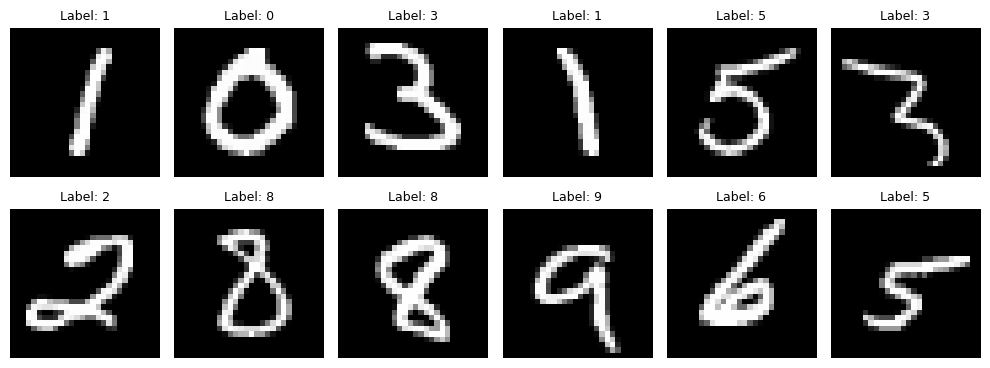

In [8]:
# Display a few digit examples.
fig, axes = plt.subplots(2, 6, figsize=(10, 3.9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images_train[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Label: {y_train[i]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 2. Worked example: SVM classification

A Support Vector Machine (SVM) classifies each image by using its **784 pixel values as features**. This revises the original Lab 6 SVM notebook into a concise MNIST baseline so that you can compare the models under the same train/test split.

An SVM baseline is provided because **Activity 1 asks you to compare KNN against SVM**.

In [9]:
def evaluate_classifier(name, true_labels, predicted_labels):
    accuracy = accuracy_score(true_labels, predicted_labels)
    print(f'{name} held-out accuracy: {accuracy:.2%}')
    return accuracy

results = {}
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)
results['SVM (linear)'] = evaluate_classifier('SVM (linear)', y_test, svm_predictions)
print('Classification report:')
print(classification_report(y_test, svm_predictions, digits=3))

SVM (linear) held-out accuracy: 91.05%
Classification report:
              precision    recall  f1-score   support

           0      0.964     0.954     0.959       197
           1      0.949     0.996     0.972       223
           2      0.864     0.925     0.893       199
           3      0.865     0.870     0.867       207
           4      0.872     0.876     0.874       194
           5      0.902     0.818     0.858       181
           6      0.964     0.959     0.962       197
           7      0.936     0.909     0.922       209
           8      0.930     0.892     0.911       194
           9      0.859     0.889     0.874       199

    accuracy                          0.910      2000
   macro avg      0.911     0.909     0.909      2000
weighted avg      0.911     0.910     0.910      2000



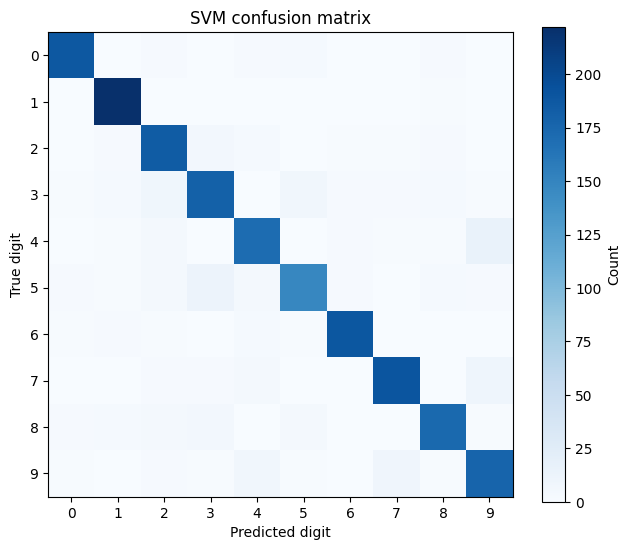

In [10]:
# Confusion matrix: rows are the true digits, columns are predicted digits.
cm = confusion_matrix(y_test, svm_predictions, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap='Blues')
ax.set(xticks=range(10), yticks=range(10), xlabel='Predicted digit',
       ylabel='True digit', title='SVM confusion matrix')
fig.colorbar(im, ax=ax, label='Count')
plt.tight_layout()
plt.show()

## 3. Activity 1: K-Nearest Neighbors (KNN)

**Your task:** Implement KNN for MNIST and compare its **held-out test accuracy** against the SVM baseline. You can use `sklearn.neighbors.KNeighborsClassifier` or implement the neighbor search and voting yourself.

1. Choose `k` (for example, start with 3 or 5).
2. Train on `X_train, y_train` and predict on `X_test`.
3. Report accuracy and explain which method performs better on the held-out split.

Fill the `TODO` below. The supplied evaluation code runs once `knn_model` is defined.

In [14]:
# TODO: Implement the KNN classifier.
knn_model = KNeighborsClassifier(n_neighbors=5)

if knn_model is not None:
    knn_model.fit(X_train, y_train)
    knn_predictions = knn_model.predict(X_test)
    results['KNN'] = evaluate_classifier('KNN', y_test, knn_predictions)
else:
    print('TODO: define knn_model above, then rerun this cell.')

KNN held-out accuracy: 95.60%


**Activity 1 result: KNN vs SVM**

- KNN (k = 5): **95.60%** held-out accuracy
- Linear SVM (C = 1.0): **91.05%** held-out accuracy

**KNN performs better** on the held-out split (+4.55 percentage points). A linear SVM can only separate the digits with linear boundaries in the 784-dimensional pixel space. Handwritten digits are not linearly separable, so it confuses similar shapes (4/9, 3/5/8, 7/9). KNN is non-parametric and classifies each image by a vote of its 5 most similar training images, which gives a flexible, non-linear decision boundary that fits the local structure of the data better. The cost is that KNN is slow at prediction time and must store the whole training set.

## 4. Activity 2: K-means clustering

**Your task:** Implement K-means for MNIST with **10 clusters**, without using the digit labels when fitting. You may use `sklearn.cluster.KMeans` or code the iterative assignment/centroid-update algorithm yourself.

K-means is **unsupervised**: cluster indices (0–9) do not automatically correspond to digit classes (0–9). **Do not calculate ordinary classification accuracy directly from cluster IDs.** Instead, inspect the cluster-label table and optionally calculate the **Adjusted Rand Index (ARI)**, which is invariant to cluster-label permutations.

In [15]:
# TODO: Create a K-means model (10 clusters) or your own equivalent.
kmeans_model = KMeans(n_clusters=10, random_state=SEED, n_init=10)

if kmeans_model is not None:
    kmeans_model.fit(X_train)  # Never pass y_train to unsupervised K-means.
    test_cluster_ids = kmeans_model.predict(X_test)
    cluster_table = pd.crosstab(
        pd.Series(y_test, name='Actual digit'),
        pd.Series(test_cluster_ids, name='Cluster ID')
    )
    print('Adjusted Rand Index:', round(adjusted_rand_score(y_test, test_cluster_ids), 3))
    display(cluster_table)
else:
    print('TODO: define kmeans_model above, then rerun this cell.')

Adjusted Rand Index: 0.358


Cluster ID,0,1,2,3,4,5,6,7,8,9
Actual digit,,,,,,,,,,
0,0,0,88,2,2,0,5,4,88,8
1,0,0,0,99,0,123,0,1,0,0
2,1,149,1,14,4,12,3,4,1,10
3,1,6,0,5,3,15,3,42,8,124
4,65,2,1,9,106,4,7,0,0,0
5,10,0,1,31,15,12,6,43,10,53
6,0,7,1,7,2,14,161,0,4,1
7,120,1,0,11,66,8,0,0,2,1
8,5,3,2,12,8,12,1,114,0,37


**Activity 2 observations: K-means (10 clusters)**

- **Adjusted Rand Index = 0.358**, which shows only moderate agreement between the clusters and the true digits (1 = perfect, 0 = random).
- **Clean clusters:** digit **2** (149/199 in cluster 1) and digit **6** (161/197 in cluster 6) mostly form their own cluster.
- **Digits split into two clusters:** **0** (88 in cluster 2 and 88 in cluster 8) and **1** (99 in cluster 3 and 123 in cluster 5). This is probably due to different writing styles, such as slanted vs upright 1s or round vs narrow 0s.
- **Digits mixed together:** **4, 7 and 9** share clusters 0 and 4 (for example, digit 9 is split 93/93 between them), and **3, 5 and 8** overlap in clusters 7 and 9. Digit 5 has no cluster of its own.
- **Conclusion:** K-means groups images by overall pixel similarity (Euclidean distance), not by digit identity. Because it never sees the labels, the number of clusters does not have to match the number of classes. That is why ARI is used instead of accuracy.

## 5. Activity 3: A compact CNN for MNIST (PyTorch)

**Your task:** Build, train, and test a **small convolutional neural network**. Aim for approximately **30,000–100,000 trainable parameters** as a guideline, not a strict constraint. The classic [LeNet-5 architecture](https://paperswithcode.com/method/lenet) is a useful reference, but you do **not** have to replicate it exactly.

Ideas to guide your architecture:
- Input images: `(batch, 1, 28, 28)`.
- Combine convolutional layers, a nonlinear activation (e.g., ReLU), and pooling.
- Use a final classifier with **10 outputs** (one per digit).
- For example, a LeNet-like pathway uses `6` and `16` convolution channels followed by fully connected layers; adapt the spatial dimensions carefully.
- Use cross-entropy loss on **raw logits**, not pre-softmaxed probabilities.

The data loaders and training/evaluation routines below are provided. **You must implement the CNN architecture.**

In [16]:
# Reuse the EXACT SAME image splits as the classical classifiers.
torch_train_x = torch.from_numpy(X_train.reshape(-1, 1, 28, 28).copy())
torch_test_x = torch.from_numpy(X_test.reshape(-1, 1, 28, 28).copy())
torch_train_y = torch.from_numpy(y_train.copy()).long()
torch_test_y = torch.from_numpy(y_test.copy()).long()

train_loader = DataLoader(
    TensorDataset(torch_train_x, torch_train_y),
    batch_size=BATCH_SIZE, shuffle=True
)
test_loader = DataLoader(
    TensorDataset(torch_test_x, torch_test_y),
    batch_size=BATCH_SIZE, shuffle=False
)
print('CNN input batch shape:', next(iter(train_loader))[0].shape)

CNN input batch shape: torch.Size([128, 1, 28, 28])


In [17]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Feature extractor (LeNet-like)
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, padding=2),   # (6, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                             # (6, 14, 14)
            nn.Conv2d(6, 16, kernel_size=5),             # (16, 10, 10)
            nn.ReLU(),
            nn.MaxPool2d(2),                             # (16, 5, 5)
        )
        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),                                # 16 * 5 * 5 = 400
            nn.Linear(16 * 5 * 5, 120),
            nn.ReLU(),
            nn.Linear(120, 84),
            nn.ReLU(),
            nn.Linear(84, 10),                           # 10 raw logits
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Change to True AFTER implementing SmallCNN above.
CNN_READY = True

In [19]:
def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    loss_total = 0.0
    for images_batch, labels_batch in loader:
        images_batch = images_batch.to(device)
        labels_batch = labels_batch.to(device)
        optimizer.zero_grad()
        logits = model(images_batch)
        loss = loss_fn(logits, labels_batch)
        loss.backward()
        optimizer.step()
        loss_total += loss.item() * len(labels_batch)
    return loss_total / len(loader.dataset)

@torch.no_grad()
def evaluate_cnn(model, loader, device):
    model.eval()
    correct = 0
    total = 0
    for images_batch, labels_batch in loader:
        logits = model(images_batch.to(device))
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels_batch.to(device)).sum().item()
        total += len(labels_batch)
    return correct / total

if CNN_READY:
    cnn_model = SmallCNN().to(DEVICE)
    parameter_count = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
    print(f'Trainable CNN parameters: {parameter_count:,}')
    if not 30_000 <= parameter_count <= 100_000:
        print('Note: 30,000–100,000 parameters is a guideline, not a hard rule.')

    optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    N_EPOCHS = 10  # Increase if there is enough time.
    for epoch in range(N_EPOCHS):
        loss = train_one_epoch(cnn_model, train_loader, optimizer, loss_fn, DEVICE)
        print(f'Epoch {epoch + 1:02d}/{N_EPOCHS} | train loss: {loss:.4f}')
    results['CNN'] = evaluate_cnn(cnn_model, test_loader, DEVICE)
    print(f'CNN held-out accuracy: {results["CNN"]:.2%}')
else:
    print('TODO: implement SmallCNN, set CNN_READY = True, and rerun the CNN cells.')

Trainable CNN parameters: 61,706
Epoch 01/10 | train loss: 1.2559
Epoch 02/10 | train loss: 0.3777
Epoch 03/10 | train loss: 0.2679
Epoch 04/10 | train loss: 0.2128
Epoch 05/10 | train loss: 0.1537
Epoch 06/10 | train loss: 0.1354
Epoch 07/10 | train loss: 0.1058
Epoch 08/10 | train loss: 0.0988
Epoch 09/10 | train loss: 0.0806
Epoch 10/10 | train loss: 0.0688
CNN held-out accuracy: 96.95%


## 6. Compare your models

Use the same held-out test split to report SVM, KNN, and CNN accuracies. Discuss the computational tradeoffs and whether the CNN's spatial inductive bias helps. **Do not compare K-means cluster IDs using classification accuracy**: clustering has a different objective.

In [20]:
comparison = pd.DataFrame(
    [{'Model': name, 'Held-out accuracy': value} for name, value in results.items()]
).sort_values('Held-out accuracy', ascending=False)
display(comparison.style.format({'Held-out accuracy': '{:.2%}'}))
if len(comparison) < 3:
    print('Complete KNN and CNN above to finish the three-way comparison.')

,Model,Held-out accuracy
2,CNN,96.95%
1,KNN,95.60%
0,SVM (linear),91.05%


**Discussion: model comparison**

**Results (same 2,000-image held-out split):** CNN **96.95%** > KNN **95.60%** > linear SVM **91.05%**.

**Computational tradeoffs:**
- **Linear SVM:** It solves a quadratic optimisation problem with one-vs-one classifiers (45 pairs), so training is slow for large datasets, but prediction is fast. A linear boundary on raw pixels is too simple, so it gives the lowest accuracy.
- **KNN:** It has no real training (it just stores the data), but prediction is expensive. Every test image is compared with all 10,000 training images, and the whole training set must be kept in memory. It works well here because similar digits are close in pixel space.
- **CNN:** It needs iterative training (10 epochs with Adam), which benefits from a GPU, but prediction is fast and the model is small (**61,706 trainable parameters**, LeNet-like: Conv(6) → Pool → Conv(16) → Pool → FC 120 → 84 → 10).

**Does the CNN's spatial inductive bias help?** Yes. SVM and KNN treat each image as a flat vector of 784 independent pixels, so a small shift or slant changes many features. The CNN uses local convolution filters with shared weights and pooling, so it learns local patterns (edges, strokes, curves) and is more robust to small translations and distortions. That is why it reaches the highest accuracy with relatively few parameters. With more epochs or more training data, the gap would likely grow.

**K-means** is not included in the accuracy comparison, because it is unsupervised and its cluster IDs do not correspond to digit labels. It is evaluated with ARI (0.358) instead.

## 7. Extended activity

Identify another suitable ML method for MNIST (for example, logistic regression or a random forest). Explain when it might be preferable, considering accuracy, training time, interpretability, and data efficiency.

### References

- [Original MNIST dataset description](https://yann.lecun.com/exdb/mnist/)
- [Scikit-learn SVM](https://scikit-learn.org/stable/modules/svm.html)
- [Scikit-learn KNN](https://scikit-learn.org/stable/modules/neighbors.html)
- [Scikit-learn K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)
- [LeNet-5 reference](https://paperswithcode.com/method/lenet)
- [PyTorch documentation](https://pytorch.org/docs/stable/index.html)

**What to report:** KNN accuracy versus SVM; K-means clustering observations and ARI (optional); CNN test accuracy and trainable parameter count; a short cross-model comparison.

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
results['Random Forest'] = evaluate_classifier('Random Forest', y_test, rf_predictions)

Random Forest held-out accuracy: 95.40%


**Extended activity: Random Forest**

A Random Forest is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the data and a random subset of the features, and the final prediction is a majority vote. On our split it reached **95.40%**, which is close to KNN (95.60%), better than the linear SVM (91.05%) and below the CNN (96.95%).

**When it might be preferable:**
- **Accuracy:** It is competitive with KNN and clearly better than a linear SVM, because it captures non-linear pixel interactions, but it is below a CNN because it has no spatial inductive bias.
- **Training time:** It is fast (a few seconds on CPU), the trees train in parallel, and it needs no GPU and little tuning. Prediction is also much faster than KNN, because it does not compare each test image with every training image.
- **Interpretability:** It gives feature importances, so we can visualize which pixels matter most (as a 28×28 heat map). That is easier to explain than CNN weights.
- **Data efficiency:** It works well with small or medium tabular datasets and needs no feature scaling. For large image datasets, though, CNNs scale better and reach higher accuracy.

**Conclusion:** A Random Forest is a good choice when we need a fast, CPU-friendly and more interpretable baseline. A CNN is preferred when maximum accuracy on images matters and GPU training is available.

**Summary of results:**
| Model | Held-out accuracy |
|---|---|
| CNN (61,706 parameters, 10 epochs) | 96.95% |
| KNN (k = 5) | 95.60% |
| Random Forest (200 trees) | 95.40% |
| SVM (linear) | 91.05% |
| K-means (10 clusters) | ARI = 0.358 (unsupervised, no accuracy) |